In [1]:
#import dependencies: https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/stanford_dogs/stanford_dogs_dataset_builder.py
import collections
import os
import re
import xml.etree.ElementTree as ET
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets.public_api as tfds 
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#to check 
print ("done importing")

/Users/selinacheah/miniforge3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


done importing


In [2]:
os.getcwd()

'/Users/selinacheah/tensorflow-capstone'

In [3]:
#load dataset
#dataset is downloaded from http://vision.stanford.edu/aditya86/ImageNetDogs/main.html
#make sure dataset is in the same directory!
import tarfile 
file_list = os.listdir('.')
file_list

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'Images',
 'test_data.mat',
 'inceptionV3_model_fineTuning.h5',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'env',
 'test_list.mat',
 'history_featureExtraction_2.npy',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'WoofAmI_Training.ipynb',
 'WoofAmI.ipynb',
 'WoofAmI-Evaluation.ipynb']

In [4]:
#extract tar files 
for fname in file_list:
    if fname.endswith(".tar"):
        tar = tarfile.open(fname, "r:")
        tar.extractall()
        tar.close
        

In [5]:
#to check .tar files are extracted
os.listdir(".")

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'Images',
 'test_data.mat',
 'inceptionV3_model_fineTuning.h5',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'env',
 'test_list.mat',
 'history_featureExtraction_2.npy',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'WoofAmI_Training.ipynb',
 'WoofAmI.ipynb',
 'WoofAmI-Evaluation.ipynb']

In [6]:
#import dependencies for training
import numpy as np
from matplotlib import pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential 
import pathlib 

print("imported")

imported


In [7]:
dataset_dir = 'Images'
os.listdir(dataset_dir)

['n02097658-silky_terrier',
 'n02092002-Scottish_deerhound',
 'n02099849-Chesapeake_Bay_retriever',
 'n02091244-Ibizan_hound',
 'n02095314-wire-haired_fox_terrier',
 'n02091831-Saluki',
 'n02102318-cocker_spaniel',
 'n02104365-schipperke',
 'n02090622-borzoi',
 'n02113023-Pembroke',
 'n02105505-komondor',
 'n02093256-Staffordshire_bullterrier',
 'n02113799-standard_poodle',
 'n02109961-Eskimo_dog',
 'n02089973-English_foxhound',
 'n02099601-golden_retriever',
 'n02095889-Sealyham_terrier',
 'n02085782-Japanese_spaniel',
 'n02097047-miniature_schnauzer',
 'n02110063-malamute',
 'n02105162-malinois',
 'n02086079-Pekinese',
 'n02097130-giant_schnauzer',
 'n02113978-Mexican_hairless',
 'n02107142-Doberman',
 'n02097209-standard_schnauzer',
 'n02115913-dhole',
 'n02106662-German_shepherd',
 'n02106382-Bouvier_des_Flandres',
 'n02110185-Siberian_husky',
 'n02094258-Norwich_terrier',
 'n02093991-Irish_terrier',
 'n02094114-Norfolk_terrier',
 'n02109525-Saint_Bernard',
 'n02093754-Border_terri

In [8]:
#building data pipeline : https://www.youtube.com/watch?v=jztwpsIzEGc
data = tf.keras.utils.image_dataset_from_directory('Images')

Found 20580 files belonging to 120 classes.


In [9]:
#access data pipeline
data_iterator = data.as_numpy_iterator()
data_iterator

In [10]:
#data augmentation
train_gen = ImageDataGenerator(validation_split=0.2, 
                               rescale=1.0/255.0,
                                width_shift_range=0.2, # 0.1
                                height_shift_range=0.2, # 0.1
                                horizontal_flip=True)

train_set = train_gen.flow_from_directory(
                               directory=dataset_dir,
                               seed=10,
                               class_mode='sparse',
                               batch_size=32,
                               shuffle=True,
                               target_size=(224, 224),
                               subset='training')



Found 16508 images belonging to 120 classes.


In [11]:
#avoid augmentation in validation to represent real-world scenarios
val_gen = ImageDataGenerator(validation_split=0.2, 
                                rescale=1.0/255.0,
                                )

val_set = val_gen.flow_from_directory(
                               directory=dataset_dir,
                               seed=10,
                               class_mode='sparse',
                               batch_size=32,
                               shuffle=True,
                               target_size=(224, 224),
                               subset='validation')



Found 4072 images belonging to 120 classes.


In [12]:
#added
class_names = {y: x for x, y in val_set.class_indices.items()}
class_names

{0: 'n02085620-Chihuahua',
 1: 'n02085782-Japanese_spaniel',
 2: 'n02085936-Maltese_dog',
 3: 'n02086079-Pekinese',
 4: 'n02086240-Shih-Tzu',
 5: 'n02086646-Blenheim_spaniel',
 6: 'n02086910-papillon',
 7: 'n02087046-toy_terrier',
 8: 'n02087394-Rhodesian_ridgeback',
 9: 'n02088094-Afghan_hound',
 10: 'n02088238-basset',
 11: 'n02088364-beagle',
 12: 'n02088466-bloodhound',
 13: 'n02088632-bluetick',
 14: 'n02089078-black-and-tan_coonhound',
 15: 'n02089867-Walker_hound',
 16: 'n02089973-English_foxhound',
 17: 'n02090379-redbone',
 18: 'n02090622-borzoi',
 19: 'n02090721-Irish_wolfhound',
 20: 'n02091032-Italian_greyhound',
 21: 'n02091134-whippet',
 22: 'n02091244-Ibizan_hound',
 23: 'n02091467-Norwegian_elkhound',
 24: 'n02091635-otterhound',
 25: 'n02091831-Saluki',
 26: 'n02092002-Scottish_deerhound',
 27: 'n02092339-Weimaraner',
 28: 'n02093256-Staffordshire_bullterrier',
 29: 'n02093428-American_Staffordshire_terrier',
 30: 'n02093647-Bedlington_terrier',
 31: 'n02093754-Border_

In [13]:
#added
num_classification_categories = len(class_names)
print('Number of classes=%d' % num_classification_categories)

Number of classes=120


In [14]:
batch = data_iterator.next() #retrieve a batch of data from iterator 
batch

(array([[[[7.89918213e+01, 1.26991821e+02, 2.79918213e+01],
          [8.75824585e+01, 1.35582458e+02, 3.47342529e+01],
          [7.28897705e+01, 1.21272583e+02, 1.73585205e+01],
          ...,
          [9.14230347e+01, 1.40188660e+02, 3.04230347e+01],
          [8.64174805e+01, 1.28276855e+02, 2.49788818e+01],
          [9.48169556e+01, 1.35816956e+02, 3.38087769e+01]],
 
         [[7.82396851e+01, 1.26180542e+02, 2.72407837e+01],
          [8.61486206e+01, 1.34101746e+02, 3.46954956e+01],
          [7.52074585e+01, 1.23557861e+02, 1.96527710e+01],
          ...,
          [8.55124512e+01, 1.34278076e+02, 2.44979858e+01],
          [8.72234497e+01, 1.29139771e+02, 2.46397705e+01],
          [8.96316528e+01, 1.30678528e+02, 2.75613403e+01]],
 
         [[9.01445923e+01, 1.35602539e+02, 3.92695923e+01],
          [8.66408691e+01, 1.32618591e+02, 3.42557373e+01],
          [9.35506592e+01, 1.40550659e+02, 3.70493164e+01],
          ...,
          [8.12955322e+01, 1.30061157e+02, 1.9678

In [15]:
len(batch)
#calculates no. of elements in the 'batch'. Batch is composed of 2 parts, images and labels

2

In [16]:
#images represented as numpy array
batch[0].shape #image
#shape of an image is represented as (height, width, channels), dimensions and the number of color channels (e.g., 3 for RGB)

(32, 256, 256, 3)

In [17]:
batch[1] #labels

array([ 74,  74,  56, 115, 119,  66, 100,  28,  24,  72,  50,  38,   4,
        75,  51,  89,  44, 113,  53, 118,  37,  86,   2, 106,  78,  73,
        84,  16,  11,  23,  61,  87], dtype=int32)

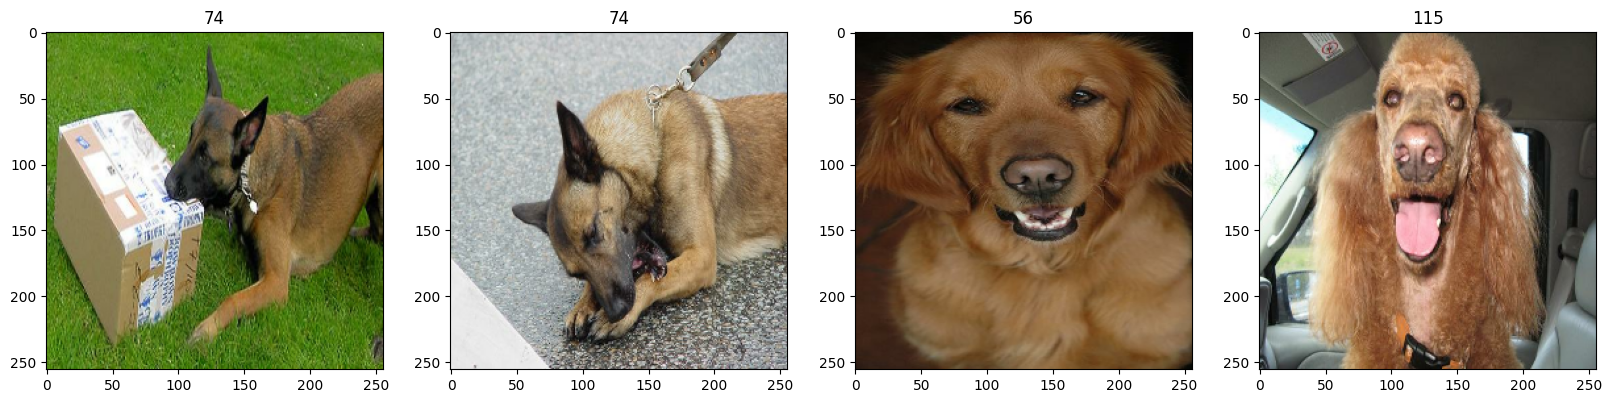

In [18]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx]) 

In [19]:
# making values smaller for optimization, range 0-1 (255 is max of rgb)
scaled = batch[0]/255 

In [20]:
scaled.max()

1.0

In [21]:
#preprocessing data - transform raw data into a format suitable for analysis  
#scale data : https://www.tensorflow.org/api_docs/python/tf/data/Dataset#map
data = data.map(lambda x,y: (x/255, y))

In [22]:
scaled_iterator = data.as_numpy_iterator()

In [23]:
batch = scaled_iterator.next()

In [24]:
batch[0].max()

1.0

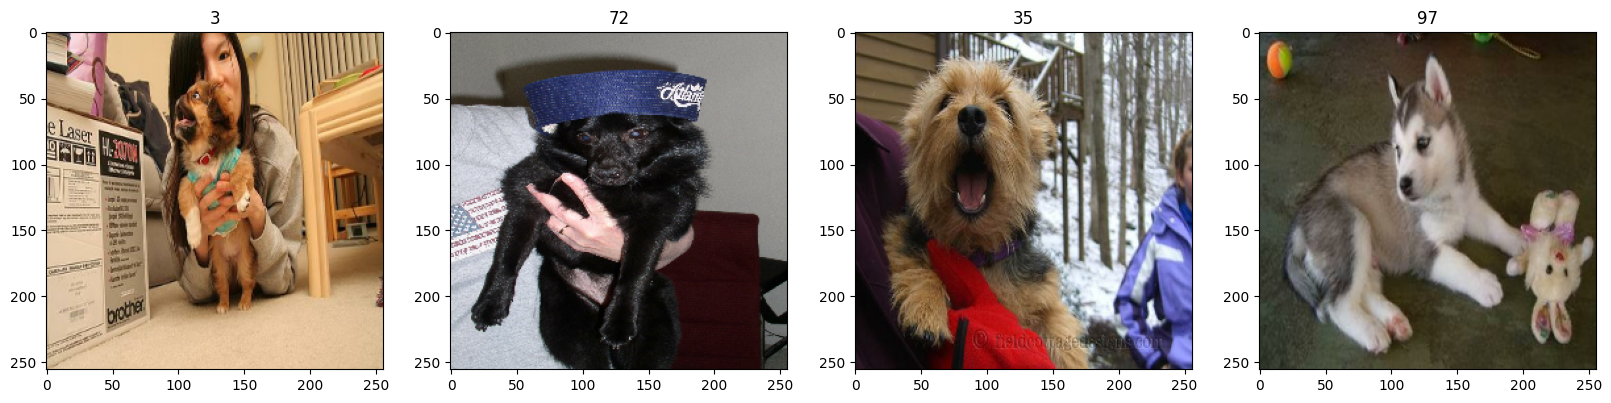

In [25]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx]) 

In [26]:
#split data 
len(data)

644

In [27]:
644*32

20608

In [28]:
train_size = int(len(data)*.7) #higher percentage for training 
val_size = int(len(data)*.2)+1 #evaluate
test_size = int(len(data)*.1)+1 #post training evaluation

print("train size =" , train_size)
print("validation size =" , val_size)
print("test size =" , test_size)

total_size = train_size + val_size + test_size
print ("total size = ", total_size)

train size = 450
validation size = 129
test size = 65
total size =  644


In [29]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [30]:
len(test)

65

In [31]:
#import libraries and pre-trained model 
from tensorflow.keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, InputLayer
from keras import layers, models
from keras.models import Sequential
from keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D, Input
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.models import Sequential, Model
from sklearn import metrics
from tqdm import tqdm


In [32]:
from keras.applications.inception_v3 import InceptionV3

In [33]:
#initialise the base model 
base_model = InceptionV3(#input_shape=(224,224,3),
                          include_top = True,
                          weights = 'imagenet')

base_model.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 149, 149, 32)         864       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 149, 149, 32)         96        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 149, 149, 32)         0         ['batch_normalizati

                                                                                                  
 conv2d_71 (Conv2D)          (None, 8, 8, 320)            552960    ['activation_70[0][0]']       
                                                                                                  
 conv2d_75 (Conv2D)          (None, 8, 8, 192)            331776    ['activation_74[0][0]']       
                                                                                                  
 batch_normalization_71 (Ba  (None, 8, 8, 320)            960       ['conv2d_71[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_75 (Ba  (None, 8, 8, 192)            576       ['conv2d_75[0][0]']           
 tchNormalization)                                                                                
          

                                                                                                  
 activation_82 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_82[0][0]
                                                                    ']                            
                                                                                                  
 activation_83 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_83[0][0]
                                                                    ']                            
                                                                                                  
 batch_normalization_84 (Ba  (None, 8, 8, 192)            576       ['conv2d_84[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activatio

                                                                                                  
 activation_88 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_88[0][0]
                                                                    ']                            
                                                                                                  
 activation_91 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_91[0][0]
                                                                    ']                            
                                                                                                  
 activation_92 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_92[0][0]
                                                                    ']                            
                                                                                                  
 batch_nor

In [34]:
#freezing all weights 
#for layer in base_model.layers:
        #layer.trainable = False
# Unfreeze all layers initially
for layer in base_model.layers:
    layer.trainable = True

# Freeze all layers except the last two -retain pre-trained knowledge
# allows model to adjust its higher level features that is closer to output layer 
for layer in base_model.layers[:-2]:
    layer.trainable = False

In [35]:
#adding fully connected layers onto model 
x = Flatten()(base_model.output) 


In [36]:
# add dropout and L2 regularization 
from keras.regularizers import l2

x = Dropout(0.5)(x)
prediction = Dense(
    num_classification_categories, 
    activation='softmax', 
    kernel_regularizer=l2(0.001)  # L2 regularization
)(x)

In [37]:
#visualise
model = models.Model(inputs=base_model.input, outputs=prediction)
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 149, 149, 32)         864       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 149, 149, 32)         96        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 149, 149, 32)         0         ['batch_normalization[0][0

                                                                                                  
 activation_88 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_88[0][0]
                                                                    ']                            
                                                                                                  
 activation_91 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_91[0][0]
                                                                    ']                            
                                                                                                  
 activation_92 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_92[0][0]
                                                                    ']                            
                                                                                                  
 batch_nor

In [38]:
#compile 
from tensorflow.keras.optimizers import Adam 
from tensorflow.keras.metrics import Precision, Recall
import scipy

model.compile(loss=keras.losses.SparseCategoricalCrossentropy(), 
                 optimizer=keras.optimizers.legacy.Adam(), #'tf.keras.optimizers.Adam` runs slowly on M1
                 metrics=['accuracy'])


In [39]:
#setting up EarlyStopping callback
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0.001, 
    patience = 10,
    verbose = 1,
    restore_best_weights = True
)

#my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', save_best_only=True)]

In [40]:
my_callbacks = [
    ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', save_best_only=True),
    early_stopping 
]

In [41]:
#fitting

history = model.fit(
    train_set,
    epochs=3,
    validation_data=val_set,
    callbacks=my_callbacks #earlystopping
)
np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']]) 


Epoch 1/3
516/516 [==============================] - ETA: 0s - loss: 4.7086 - accuracy: 0.1574

/Users/selinacheah/miniforge3/lib/python3.10/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


516/516 [==============================] - 400s 771ms/step - loss: 4.7086 - accuracy: 0.1574 - val_loss: 4.6170 - val_accuracy: 0.3490
Epoch 2/3
516/516 [==============================] - 408s 790ms/step - loss: 4.5724 - accuracy: 0.1699 - val_loss: 4.4992 - val_accuracy: 0.3433
Epoch 3/3
516/516 [==============================] - 414s 802ms/step - loss: 4.4825 - accuracy: 0.1696 - val_loss: 4.4044 - val_accuracy: 0.3409


In [43]:
#function to gradually unfreeze layers 
def unfreeze_model(model, layers_to_unfreeze):
    #freeze all layers first 
    for layer in model.layers:
        layer.trainable = False

    #unfreeze some layers 
    for layer in model.layers[-layers_to_unfreeze:]:
        layer.trainable = True

    #compile the model after unfreezing 
    model.compile(loss=keras.losses.SparseCategoricalCrossentropy(), 
                  optimizer=keras.optimizers.legacy.Adam(),
                  metrics=['accuracy'])
    

In [44]:
#Phase 2- unfreeze more layers
unfreeze_model(model, 10)
history = model.fit(
    train_set,
    epochs=2,
    validation_data=val_set,
    callbacks=my_callbacks #earlystopping
)
np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']]) 

Epoch 1/2
516/516 [==============================] - 408s 787ms/step - loss: 4.3984 - accuracy: 0.1762 - val_loss: 4.3289 - val_accuracy: 0.3495
Epoch 2/2
516/516 [==============================] - 400s 776ms/step - loss: 4.3283 - accuracy: 0.1803 - val_loss: 4.2556 - val_accuracy: 0.3497


In [46]:
#fine-tuning 
# load base InceptionV3 model w/o its top layers
base_model = InceptionV3(
    include_top=False, 
    weights='imagenet', 
    input_shape=(224, 224, 3)
)

In [47]:
# freeze the base model layers 
for layer in base_model.layers:
    layer.trainable = False
    

In [48]:
# add new layers
x = layers.Flatten()(base_model.output)

x = layers.Dropout(0.5)(x) #regularization

prediction = layers.Dense(num_classification_categories, activation='softmax', kernel_regularizer=l2(0.001))(x)


In [49]:
# create new model 
model = models.Model(inputs=base_model.input, outputs = prediction)


In [50]:
# compile the model 
model.compile(optimizer=tf.keras.optimizers.legacy.Adam(), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy']
             )


In [51]:
# Set up callbacks
early_stopping = EarlyStopping(
    monitor='val_loss', 
    min_delta=0.001, 
    patience=10, 
    verbose=1, 
    restore_best_weights=True)

my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', 
                                save_best_only=True), 
                early_stopping]



In [52]:
# Train the model
history = model.fit(
    train_set, 
    epochs=3, 
    validation_data=val_set, 
    callbacks=my_callbacks
)


Epoch 1/3
516/516 [==============================] - 406s 782ms/step - loss: 12.0343 - accuracy: 0.5806 - val_loss: 11.7586 - val_accuracy: 0.6928
Epoch 2/3
516/516 [==============================] - 398s 770ms/step - loss: 13.5355 - accuracy: 0.6842 - val_loss: 14.7898 - val_accuracy: 0.7250
Epoch 3/3
516/516 [==============================] - 404s 783ms/step - loss: 14.8204 - accuracy: 0.7138 - val_loss: 17.0299 - val_accuracy: 0.7220


In [53]:
# unfreeze the last few layers for fine-tuning 
num_layers_to_unfreeze = 10
for layer in base_model.layers [-num_layers_to_unfreeze:]:
    layer.trainable = True

In [54]:
# compile model with a smaller learning rate 
model.compile(optimizer=keras.optimizers.legacy.Adam(learning_rate=1e-5), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy']
             )


In [55]:
# train the model
history_fine = model.fit(train_set, 
                         epochs=5, 
                         validation_data=val_set, 
                         callbacks=my_callbacks
                        )


Epoch 1/5
516/516 [==============================] - 435s 839ms/step - loss: 12.4801 - accuracy: 0.7644 - val_loss: 13.8328 - val_accuracy: 0.7650
Epoch 2/5
516/516 [==============================] - 419s 812ms/step - loss: 11.0633 - accuracy: 0.7931 - val_loss: 13.1147 - val_accuracy: 0.7711
Epoch 3/5
516/516 [==============================] - 398s 771ms/step - loss: 10.3405 - accuracy: 0.8075 - val_loss: 12.7827 - val_accuracy: 0.7750
Epoch 4/5
516/516 [==============================] - 396s 768ms/step - loss: 10.2962 - accuracy: 0.8047 - val_loss: 12.6078 - val_accuracy: 0.7775
Epoch 5/5
516/516 [==============================] - 398s 772ms/step - loss: 10.0806 - accuracy: 0.8071 - val_loss: 12.4528 - val_accuracy: 0.7819


In [58]:
#Test Data Generator
test_gen = ImageDataGenerator(rescale=1.0/255.0)

test_set = test_gen.flow_from_directory(
    directory=os.path.join(dataset_dir, 'test'),
    class_mode='sparse',
    batch_size=32,
    shuffle=False,
    target_size=(224, 224)
)


FileNotFoundError: [Errno 2] No such file or directory: 'Images/test'